# Project 4: Spotify — Pass 10

## Problem Definition


#### Business Problem

This project aims to predict the popularity of unreleased songs shortly following release, based on song data from Spotify's Top 200 Weekly (Global) charts from 2020 and 2021. Companies like Spotify may wish to understand and predict what types of tracks become hits and go viral, as these tracks can be promoted better and charge more for advertising.

#### Data Science Problem

Song popularity will be predicted using one of three different tree-based regression models: decision-tree, random forest, and xgboost.

Popularity is a continuous, numeric floating-point value. As such, this is a supervised regression problem, where the target of the prediction is the upcoming popularity of a prospective track release.

(Note: For passes 1-3, transactions data from Project 1 will be used. Similarly, for passes 4-6, housing data from Project 2 will be used. Passes 7-10 will utilize the spotify data particular to the above problem statement, with pass 10 having the most comprehensive use.)

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

import requests
from google.colab import userdata
import os

## Data Collection/Sources


### Authenticate to Hugging Face


In [2]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:3]} ... {_[-4:]}"

'hf_ ... Tuux'

In [3]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'timnickellddds'

In [4]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [5]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `Colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Read parquet from Hugging Face


In [6]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/spotify-numeric-alt.parquet"
hf_url


'https://huggingface.co/datasets/timnickellddds/Data_Science-22/resolve/main/spotify-numeric-alt.parquet'

In [7]:
df_parquet = pd.read_parquet( hf_url )
df_parquet.shape


(1545, 11)

In [8]:
df_parquet.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1545 entries, 0 to 1544
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Streams           1545 non-null   int64  
 1   Artist Followers  1545 non-null   int64  
 2   Danceability      1545 non-null   float64
 3   Energy            1545 non-null   float64
 4   Loudness          1545 non-null   float64
dtypes: float64(3), int64(2)
memory usage: 60.5 KB


## Data Cleaning


In [9]:
df = df_parquet

Basic Cleaning/Inspection

In [10]:
df.head()

,Streams,Artist Followers,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence
0,48633449,3377762,0.714,0.800,-4.808,0.0504,0.1270,0.3590,134.002,211560,0.589
1,47248719,2230022,0.591,0.764,-5.484,0.0483,0.0383,0.1030,169.928,141806,0.478
2,40162559,6266514,0.563,0.664,-5.044,0.1540,0.3350,0.0849,166.928,178147,0.688
3,37799456,83293380,0.808,0.897,-3.712,0.0348,0.0469,0.3640,126.026,231041,0.591
4,33948454,5473565,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894


In [11]:
df.tail()

,Streams,Artist Followers,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence
1540,4630675,27167675,0.762,0.700,-6.021,0.0694,0.00261,0.1530,116.073,209320,0.608
1541,4623030,15019109,0.528,0.870,-3.123,0.0851,0.24000,0.3330,152.370,181930,0.714
1542,4620876,22698747,0.765,0.523,-4.333,0.0300,0.18400,0.1320,104.988,217307,0.394
1543,4607385,208630,0.832,0.550,-7.026,0.0587,0.24900,0.1820,154.064,152784,0.881
1544,4595450,42227614,0.448,0.603,-7.176,0.0640,0.43300,0.0862,205.272,221307,0.422


In [12]:
df.shape

(1545, 11)

In [13]:
df.size

16995

In [14]:
df.describe().transpose().head()

,count,mean,std,min,25%,50%,75%,max
Streams,1545.0,6.337136e+06,3.375402e+06,4176083.000,4915080.000,5269163.000,6.452492e+06,4.863345e+07
Artist Followers,1545.0,1.471690e+07,1.667579e+07,4883.000,2123734.000,6852509.000,2.269875e+07,8.333778e+07
Danceability,1545.0,6.899968e-01,1.424440e-01,0.150,0.599,0.707,7.960000e-01,9.800000e-01
Energy,1545.0,6.334951e-01,1.615770e-01,0.054,0.532,0.642,7.520000e-01,9.700000e-01
Loudness,1545.0,-6.348474e+00,2.509281e+00,-25.166,-7.491,-5.990,-4.711000e+00,1.509000e+00


In [15]:
df.isnull().sum()*1000

,0
Streams,0
Artist Followers,0
Danceability,0
Energy,0
Loudness,0
Speechiness,0
Acousticness,0
Liveness,0
Tempo,0
Duration (ms),0


In [16]:
row_nulls_count = int(df.isnull().sum().sum())
row_nulls_count

0

In [17]:
print(f"Rows containing nulls: {row_nulls_count}")

Rows containing nulls: 0


In [18]:
# No data cleaning necessary for this pass:
# data cleaning performed in previous project pass.
# See Project 4 Pass 07a for reference.

## Exploratory Data Analysis


In [19]:
target_col = 'Streams'

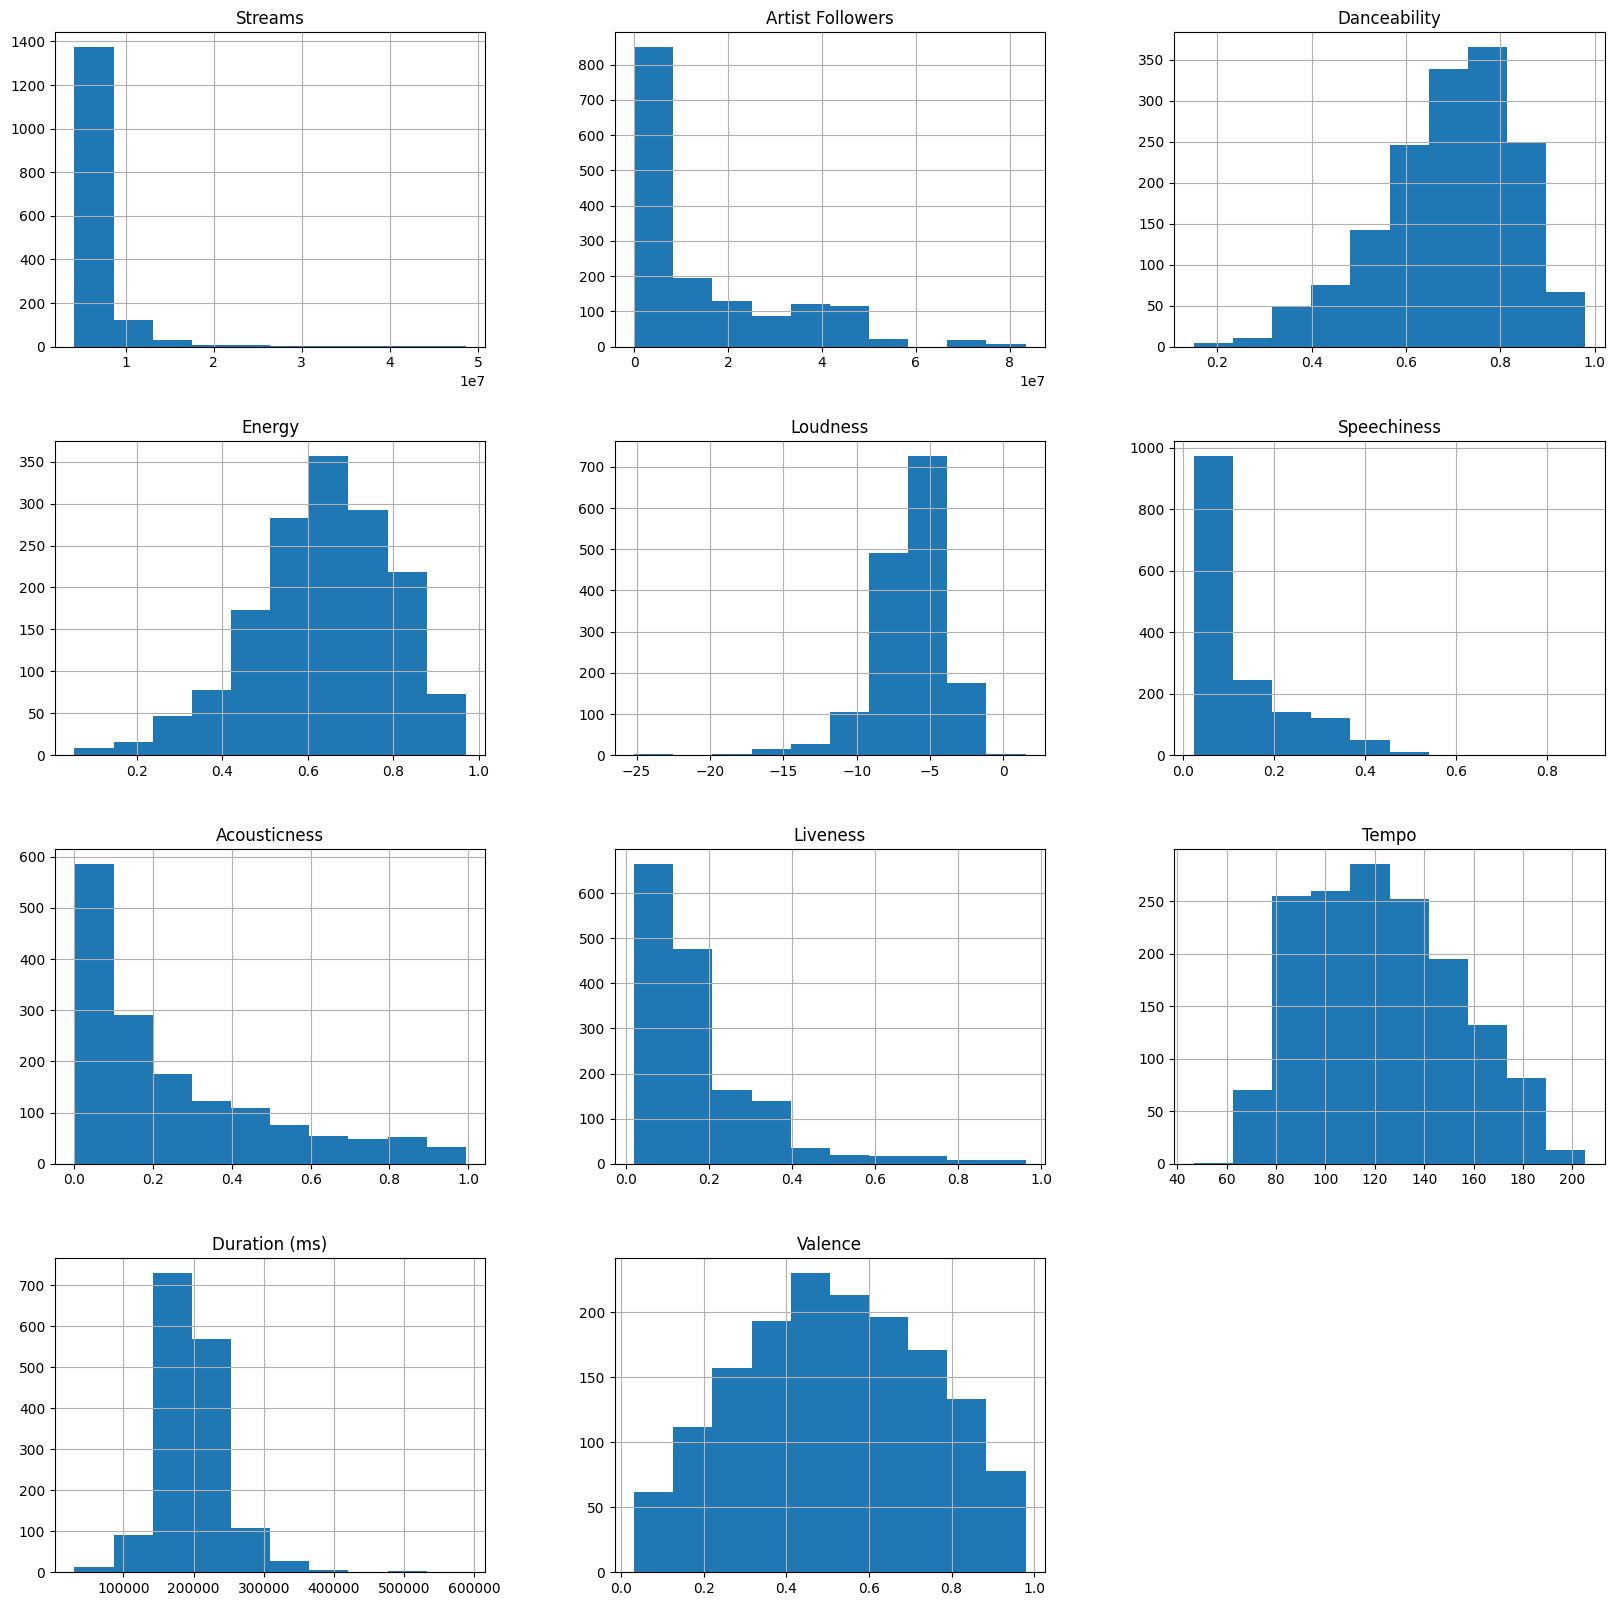

In [20]:
# Display a histogram
df.hist(figsize=(20, 20)) ;

Text(70.72222222222221, 0.5, 'Features')

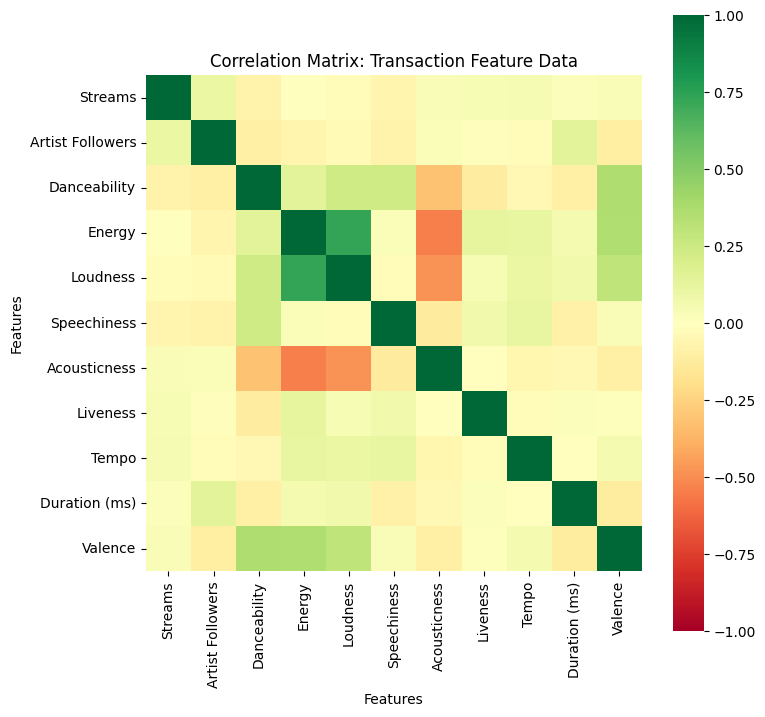

In [21]:
# column correlations
column_correlations = df.corr()

# Display correlation matrix
plt.figure(figsize = (8, 8))
sns.heatmap(
    column_correlations,
    annot = False,
    square = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)
plt.title("Correlation Matrix: Transaction Feature Data")
plt.xlabel("Features")
plt.ylabel("Features")

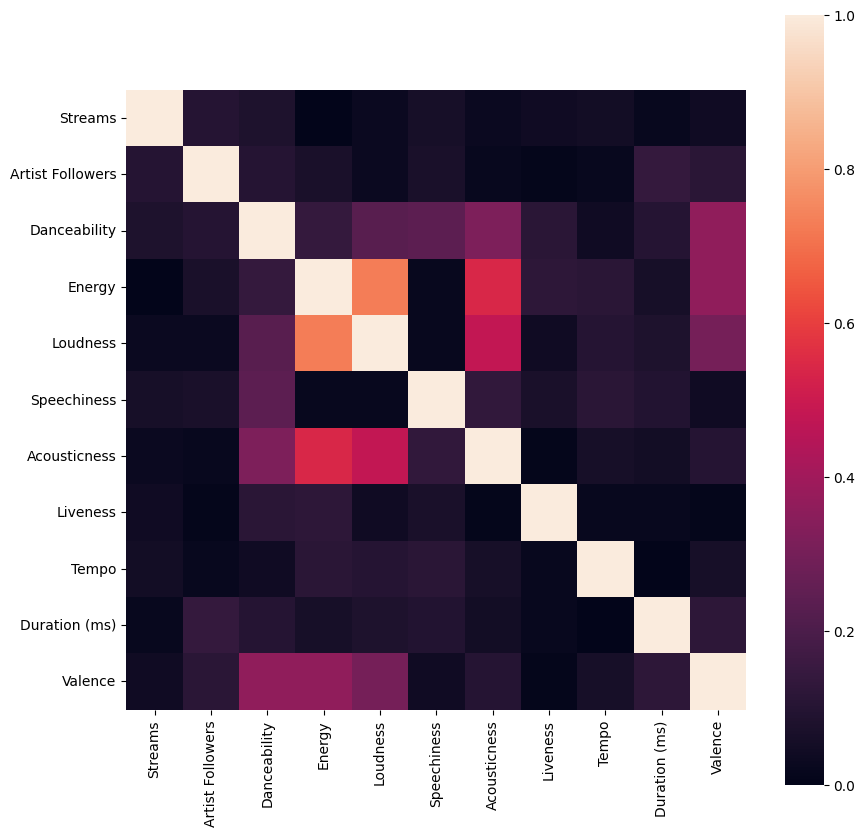

In [22]:
# Correlation plot — target and features
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;


In [23]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,Streams
Streams,1.00
Artist Followers,0.10
Danceability,0.08
Speechiness,0.06
Tempo,0.05
Liveness,0.04
Valence,0.04
Loudness,0.03
Acousticness,0.03
Duration (ms),0.02


<Axes: >

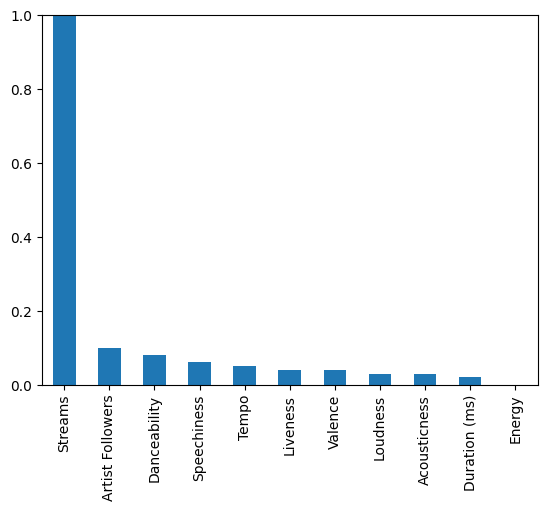

In [24]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [25]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()

,level_0,level_1,0
0,Streams,Streams,1.00
1,Streams,Artist Followers,0.10
2,Streams,Danceability,0.08
3,Streams,Energy,0.00
4,Streams,Loudness,0.03
...,...,...,...
116,Valence,Acousticness,0.10
117,Valence,Liveness,0.01
118,Valence,Tempo,0.06
119,Valence,Duration (ms),0.12


In [26]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,Streams,Artist Followers,0.10
1,Streams,Danceability,0.08
2,Streams,Energy,0.00
3,Streams,Loudness,0.03
4,Streams,Speechiness,0.06
...,...,...,...
105,Valence,Speechiness,0.04
106,Valence,Acousticness,0.10
107,Valence,Liveness,0.01
108,Valence,Tempo,0.06


In [27]:
corrs.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Energy,Loudness,0.73
1,Loudness,Energy,0.73
2,Energy,Acousticness,0.54
3,Acousticness,Energy,0.54
4,Acousticness,Loudness,0.48
...,...,...,...
105,Liveness,Artist Followers,0.01
106,Energy,Streams,0.00
107,Streams,Energy,0.00
108,Tempo,Duration (ms),0.00


In [28]:
corrs.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Energy,Loudness,0.73
1,Energy,Acousticness,0.54
2,Acousticness,Loudness,0.48
3,Valence,Danceability,0.36
4,Energy,Valence,0.36
5,Danceability,Acousticness,0.32
6,Valence,Loudness,0.30
7,Speechiness,Danceability,0.24
8,Danceability,Loudness,0.23
9,Energy,Danceability,0.14


## Processing



In [29]:
target_col = 'Streams'

### Random Forest Regression

In [30]:
features = df.drop(target_col, axis = 1)
target = df[target_col]
X = features
y = target

In [31]:
# Multiple CV — loop count
n = 30

# Create array to hold results
rmses = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )

  # Create an empty model
  model = RandomForestRegressor(n_estimators = 10) # Arbitrarily choosing max_depth of 3

  # Train ( fit ) the model
  model.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = model.predict(X_test)

  # Calculate the metric and save to array
  rmses[i]  = np.sqrt(np.mean(np.square(y_test - y_pred)))

In [32]:
# Calculate mean of results
mean_rmse = rmses.mean()
mean_rmse

np.float64(3608364.43618993)

### How do we choose the number of trees?

In [33]:
loops_count = 30

num_trees = range(10,210,22)

rms_results  = np.zeros(len(num_trees))
std_results  = np.zeros(len(num_trees))

numLoops = loops_count

for n, trees in enumerate(num_trees):
  rmses  = np.zeros(numLoops)

  for i in range(0,numLoops):
    # Train Test Split
    X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )

    # Create an empty model
    # model = RandomForestRegressor(n_estimators = trees)
    model = RandomForestRegressor(
      n_estimators = trees,
      max_depth = 15,
      min_samples_leaf = 5,
      min_samples_split = 20,
      n_jobs = -1
    )

    # Train ( fit ) the model
    model.fit(X_train, y_train)

    # Make predictions using the model
    y_pred = model.predict(X_test)

    # Calculate the metric and save to array
    rmses[i]  = np.sqrt(np.mean(np.square(y_test - y_pred)))

  print(trees,' trees finished.')
  rms_results[n] = rmses.mean()
  std_results[n] = rmses.std( ddof = 1 )

10  trees finished.
32  trees finished.
54  trees finished.
76  trees finished.
98  trees finished.
120  trees finished.
142  trees finished.
164  trees finished.
186  trees finished.
208  trees finished.


In [34]:
pd.DataFrame( zip( num_trees, rms_results, std_results ), columns = "treeno RMSE STDev".split() )


,treeno,RMSE,STDev
0,10,3.449605e+06,595608.418554
1,32,3.218876e+06,493048.074565
2,54,3.444092e+06,710720.958782
3,76,3.185242e+06,558706.171820
4,98,3.369057e+06,534765.101502
5,120,3.326907e+06,621194.598700
6,142,3.445102e+06,597972.987213
7,164,3.189054e+06,594018.287587
8,186,3.119210e+06,656384.627645
9,208,3.158565e+06,545167.142720


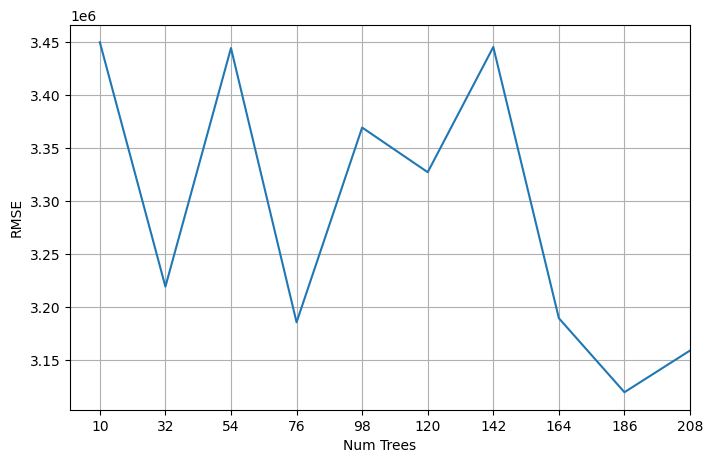

In [35]:
# Plot result
plt.figure(figsize = (8,5))
plt.plot(num_trees, rms_results)
plt.xlabel('Num Trees')
plt.ylabel('RMSE')
plt.xlim(0, 20.5)
plt.xticks(num_trees)
plt.grid()


In [36]:
# Multiple CV — loop count
n = 30

trees = 186

# Create array to hold results
rmses = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )

  # Create an empty model
  model = RandomForestRegressor(n_estimators = trees)

  # Train ( fit ) the model
  model.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = model.predict(X_test)

  # Calculate the metric and save to array
  rmses[i]  = np.sqrt(np.mean(np.square(y_test - y_pred)))

In [37]:
# Calculate mean of results
mean_rmse = rmses.mean()
mean_rmse

np.float64(3519627.7761126636)

## Data Visualization/Communication of Results


### Visualize the Random Forest

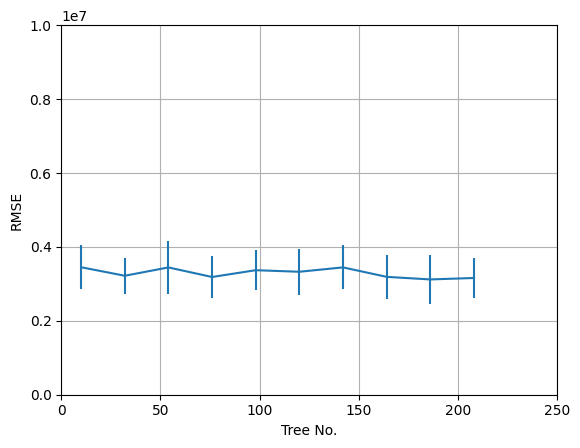

In [38]:
# plt.errorbar(num_trees, rmse_results, yerr=(std_results*2,std_results*2))
plt.errorbar(num_trees, rms_results, yerr=std_results)
plt.xlabel('Tree No.')
plt.ylabel('RMSE')
plt.ylim(0,10000000)
plt.xlim(0,250)
plt.grid()

In [39]:
import graphviz
from IPython.display import display
from sklearn import tree

In [40]:
len(model.estimators_)

186

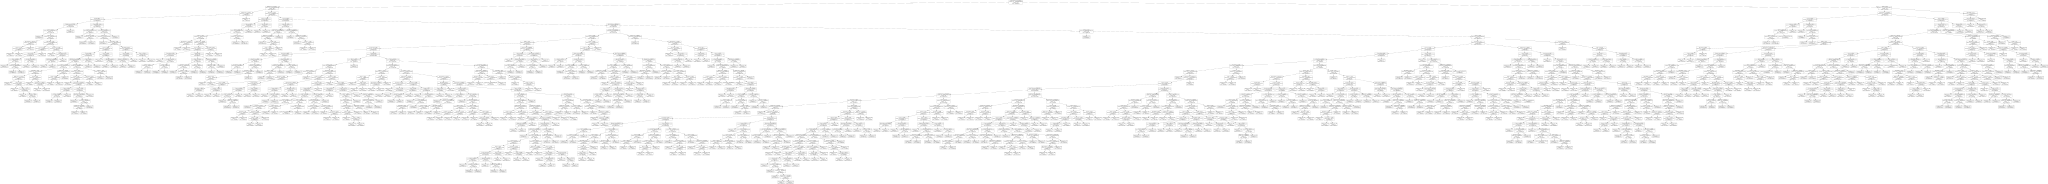

In [41]:
# Display one tree from the random forest
display(
  graphviz.Source(
    tree.export_graphviz(
      model.estimators_[0],
      feature_names = X.columns,
    )
  )
)

### Find Important Predictors

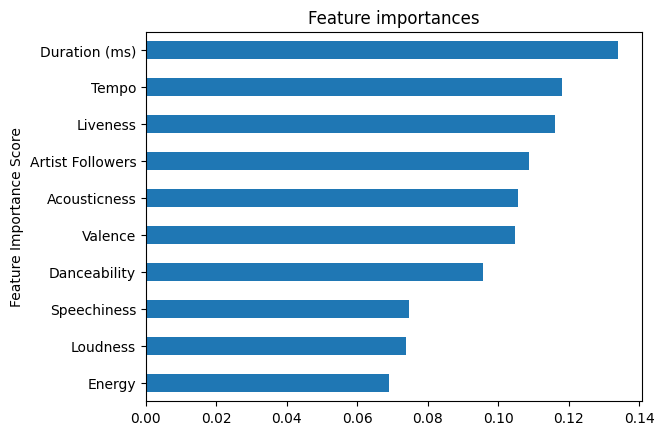

In [42]:
importances = model.feature_importances_
forest_importances = pd.Series( importances, index = X.columns )

plt.figure()
# forest_importances.plot.bar()
forest_importances.sort_values( ascending = True ).plot.barh()
plt.title("Feature importances")
plt.ylabel('Feature Importance Score') ;

In [43]:
( forest_importances.sort_values( ascending = False ) * 100 ).cumsum()

,0
Duration (ms),13.398996
Tempo,25.199588
Liveness,36.817554
Artist Followers,47.690415
Acousticness,58.245535
Valence,68.705880
Danceability,78.272427
Speechiness,85.735361
Loudness,93.104772
Energy,100.000000


### Visualize the Data

Text(0, 0.5, 'Frequency')

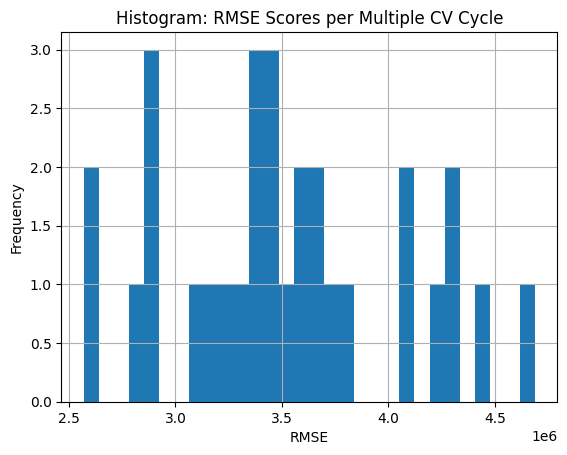

In [44]:
# Display a histogram of the results
pd.Series(rmses).hist(bins = 30)
plt.title("Histogram: RMSE Scores per Multiple CV Cycle")
plt.xlabel("RMSE")
plt.ylabel("Frequency")

In [ ]:
df['Streams'].mean()

np.float64(6337136.377993528)

## Conclusions

- The best RMSE was around 3159000, occurring at a tree number of 186.
- Random Forest yields a good result: lower rsme after iterations (from ~3600000 to ~3159000)
- Average track streams = 6337136. For songs at this value, the model should predict somewhere between 3220000 and 9480000, which is a rather wide range.
- More balanced set of predictors than when using Popularity
- change in rmse with tree depth indicates pmeaningful predictive patterns in data
- Relative to linear regression, Random Forest has the advantage of not needing to meet the requirements of linear regression (features are independent from the target), and are independent from one another (not collinear).
- Random Forest has lower error than Decision Tree, but is slower to compute RMSEs; slower than XGBoost, but lowest error overall of the three models.